### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

ROOT = Path.cwd()
if ROOT.name in {"notebook", "notebooks"}:
    ROOT = ROOT.parent

OFFICIAL = ROOT / "datasets" / "raw" / "official_report_csv"
if not OFFICIAL.exists() or not any(OFFICIAL.glob("*.csv")):
    OFFICIAL = ROOT / "datasets" / "raw" / "data" / "raw" / "official_report_csv"
if not OFFICIAL.exists():
    raise FileNotFoundError(f"Official CSV directory not found: {OFFICIAL}")
RESULTS = ROOT / "results" / "tables"

RESULTS.mkdir(parents=True, exist_ok=True)

### Load CEB datasets

In [2]:
capacity = pd.read_csv(
    OFFICIAL / "ceb_installed_capacity_by_owner_and_type_2024_2025.csv"
)

generation = pd.read_csv(
    OFFICIAL / "ceb_net_generation_by_owner_and_source_2024_2025.csv"
)

demand = pd.read_csv(
    OFFICIAL / "ceb_historical_electricity_demand_2009_2023.csv"
)

expansion = pd.read_csv(
    OFFICIAL / "ceb_base_case_solar_and_storage_additions_2025_2044.csv"
)

### Explore each dataset

In [3]:
datasets = {
    "Installed Capacity": capacity,
    "Electricity Generation": generation,
    "Historical Demand": demand,
    "Future Expansion": expansion
}

for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name)

    display(df.head(10))

    print("\nInformation:")
    df.info()

    print("\nMissing values:")
    display(df.isnull().sum())


Installed Capacity

Information:
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   owner                       12 non-null     str  
 1   plant_type                  12 non-null     str  
 2   number_of_stations_2024     12 non-null     int64
 3   number_of_stations_2025     12 non-null     int64
 4   installed_capacity_mw_2024  12 non-null     int64
 5   installed_capacity_mw_2025  12 non-null     int64
 6   source_document             12 non-null     str  
 7   source_url                  12 non-null     str  
 8   source_location             12 non-null     str  
dtypes: int64(4), str(5)
memory usage: 2.8 KB

Missing values:

Electricity Generation

Information:
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------         

,owner,plant_type,number_of_stations_2024,number_of_stations_2025,installed_capacity_mw_2024,installed_capacity_mw_2025,source_document,source_url,source_location
0,CEB,Total,29,28,3338,3261,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
1,CEB,Major Hydro,19,19,1533,1530,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
2,CEB,Thermal (Oil),8,7,801,727,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
3,CEB,Thermal (Coal),1,1,900,900,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
4,CEB,NCRE (Wind),1,1,104,104,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
5,IPP,Total,348,389,1313,1554,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
6,IPP,Thermal (Oil),2,2,482,582,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
7,IPP,NCRE (Mini Hydro),217,221,432,437,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
8,IPP,NCRE (Wind),19,19,163,163,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
9,IPP,NCRE (Other),15,16,63,64,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"


,owner,generation_source,net_generation_gwh_2024,net_generation_gwh_2025,share_of_total_percent_2024,share_of_total_percent_2025,source_document,source_url,source_location
0,CEB,Total,12861.0,12968.0,76.50,72.80,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
1,CEB,Major Hydro,5426.0,6306.0,32.30,35.40,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
2,CEB,Thermal (Oil),1568.0,1415.0,9.30,7.90,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
3,CEB,Thermal (Coal),5482.0,4870.0,32.60,27.30,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
4,CEB,NCRE (Wind),383.0,373.0,2.30,2.10,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
5,CEB,Small Islands,2.8,3.0,0.02,0.02,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
6,IPP,Total,3940.0,4845.0,23.50,27.20,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
7,IPP,Thermal (Oil),768.0,798.0,4.60,4.50,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
8,IPP,NCRE (Mini Hydro),1473.0,1425.0,8.80,8.00,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"
9,IPP,NCRE (Wind),409.0,401.0,2.40,2.30,CEB Statistical Digest 2025,https://ceb.lk/front_img/img_reports/1783568926SD-2025-Finalized-(Web-Edition).pdf,"Generation Statistics, page 2"


,year,energy_sales_gwh,energy_sales_growth_percent,transmission_distribution_losses_percent,net_generation_gwh,net_generation_growth_percent,recorded_peak_demand_mw,recorded_peak_growth_percent,source_note,source_document,source_url,source_location
0,2009,8358,0.1,14.7,9803,-0.2,1868,-2.8,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
1,2010,9191,10.0,13.7,10649,8.6,1955,4.7,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
2,2011,9973,8.5,12.2,11353,6.6,2163,10.6,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
3,2012,10389,4.2,11.4,11725,3.3,2146,-0.8,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
4,2013,10538,1.4,11.4,11898,1.5,2164,0.8,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
5,2014,10983,4.2,10.8,12316,3.5,2152,-0.6,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
6,2015,11704,6.6,10.6,13090,6.3,2283,6.1,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
7,2016,12696,8.5,10.3,14148,8.1,2453,7.4,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
8,2017,13358,5.2,9.0,14671,3.7,2523,2.9,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"
9,2018,14023,5.0,8.8,15374,4.8,2616,3.7,Annual aggregate only; not hourly/nodal. Sales aggregate CEB and LECO. Net generation includes CEB and LECO rooftop solar exported to grid from 2019 onward.,CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 3.1, printed page 3-2"


,planning_year,scenario,distribution_connected_embedded_solar_addition_mw,grid_connected_solar_addition_mw,wind_addition_mw,mini_hydro_addition_mw,biomass_addition_mw,bess_power_addition_mw,bess_energy_addition_mwh,bess_location_as_published,pumped_storage_power_addition_mw,source_note,source_document,source_url,source_location
0,2025,Base Case (70% RE target from 2030),150,50,10,10,10,5,10,NaN,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
1,2026,Base Case (70% RE target from 2030),150,220,90,10,15,100,100,Western Region,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
2,2027,Base Case (70% RE target from 2030),150,250,260,10,20,0,0,NaN,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
3,2028,Base Case (70% RE target from 2030),150,300,200,20,20,100,400,Southern Region,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
4,2029,Base Case (70% RE target from 2030),150,300,150,20,20,100,400,Not specified in table,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
5,2030,Base Case (70% RE target from 2030),150,300,150,20,20,50,50,Western Region,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
6,2031,Base Case (70% RE target from 2030),150,200,100,20,20,100,400,Not specified in table,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
7,2032,Base Case (70% RE target from 2030),150,200,100,20,20,200,800,Not specified in table,0,"Planned capacity additions in CEB long-term planning scenario, not observed operational capacity. Zero means no addition listed in the corresponding Base Case table for that year.",CEB Long Term Generation Expansion Plan 2025-2044,https://www.ceb.lk/front_img/img_reports/1748839124LTGEP-2025-2044-FINAL_c.pdf,"Table 10.1, printed pages 10-2 to 10-4"
8,2033,Base Case (70% RE target from 2030),150,200,100,20,20,100,400,Not specified in table,0,"Planned capacity additions in CEB long-term planning scenario, not observed oper

### Export an initial data inventory

In [4]:
inventory = []

for file in OFFICIAL.glob("*.csv"):

    df = pd.read_csv(file)

    inventory.append({
        "dataset": file.name,
        "records": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum())
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

inventory_df.to_csv(
    RESULTS / "official_data_inventory.csv",
    index=False
)

,dataset,records,columns,missing_cells
0,ceb_base_case_solar_and_storage_additions_2025_2044.csv,20,15,11
1,ceb_electricity_sales_by_distribution_division_2024_2025.csv,21,9,0
2,ceb_existing_renewable_capacity_as_at_2023_12_31.csv,10,9,0
3,ceb_historical_electricity_demand_2009_2023.csv,15,12,0
4,ceb_installed_capacity_by_owner_and_type_2024_2025.csv,12,9,0
5,ceb_net_generation_by_owner_and_source_2024_2025.csv,14,9,0
6,ceb_rooftop_solar_scheme_exports_2024_2025.csv,5,11,0
7,ceb_summary_statistics_2024_2025.csv,19,8,0
8,siyambalanduwa_solar_park_reference_record.csv,1,12,3


### Plot installed capacity and generation

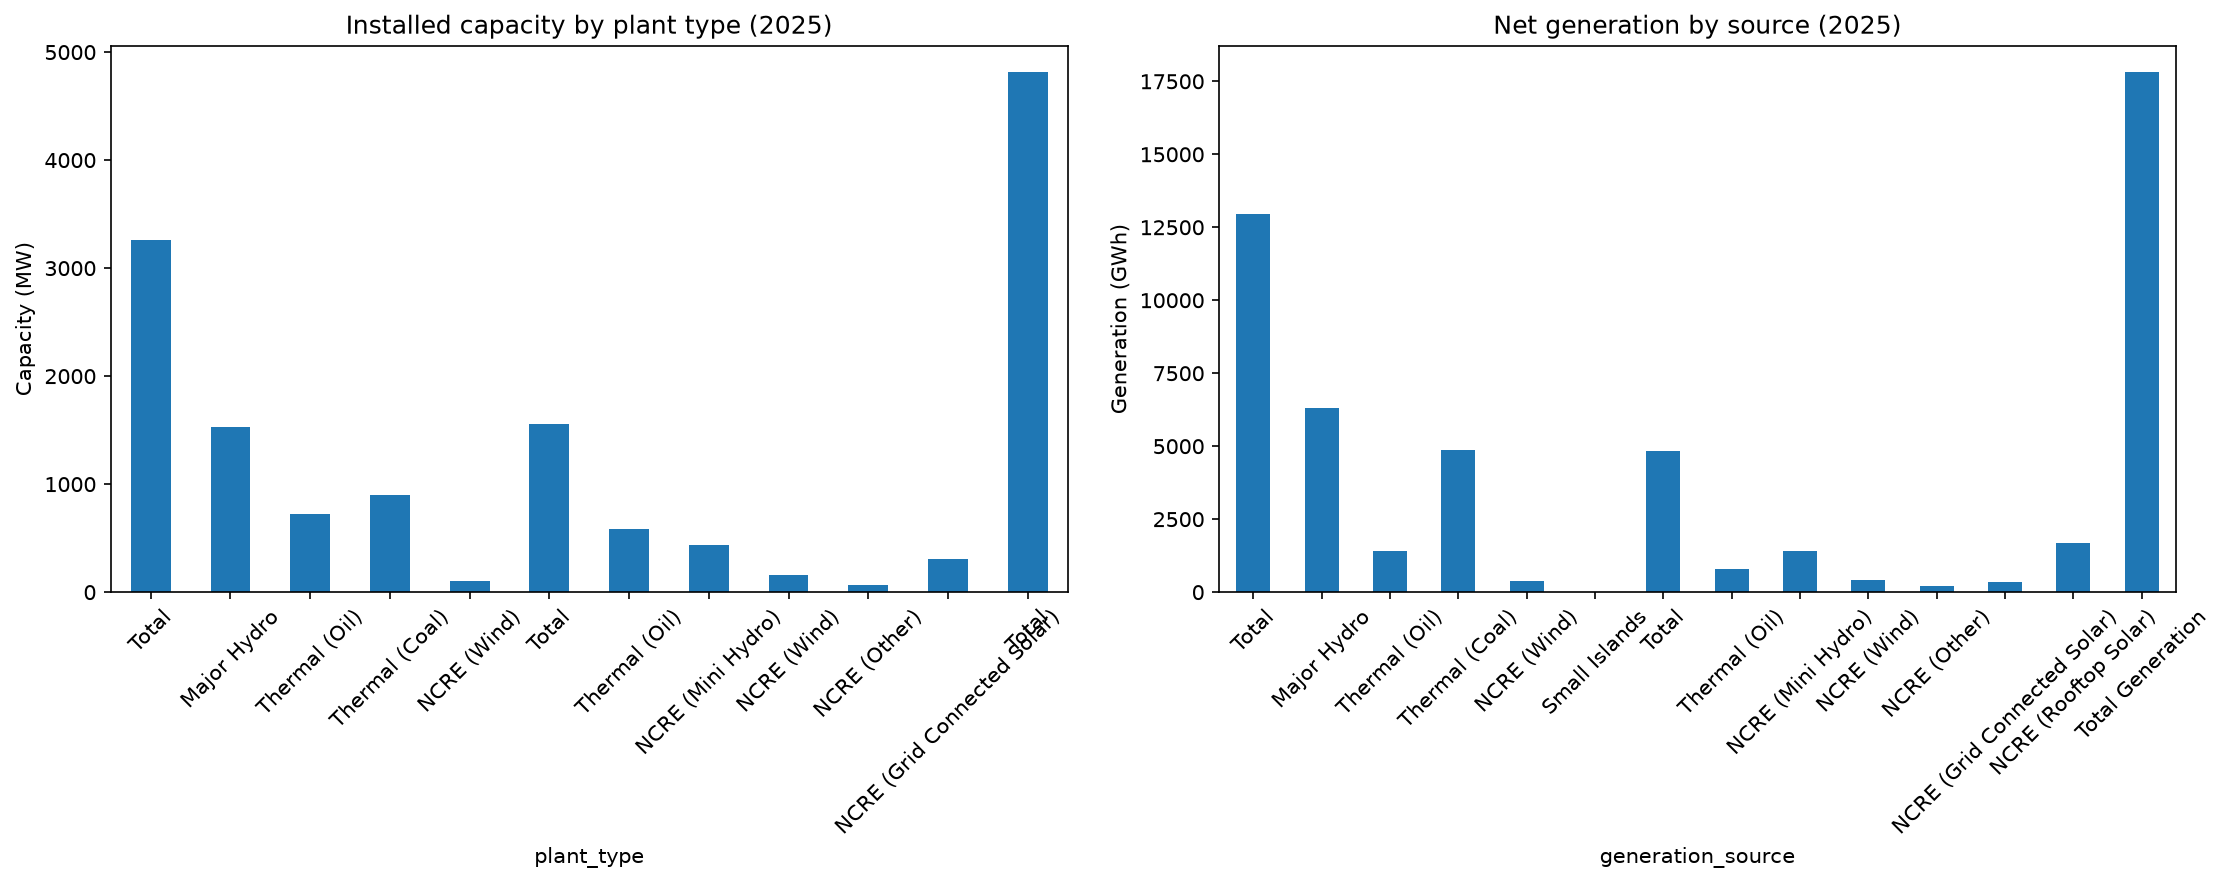

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
capacity_plot = capacity.assign(
    capacity_mw=pd.to_numeric(capacity["installed_capacity_mw_2025"], errors="coerce")
)
capacity_plot.plot(x="plant_type", y="capacity_mw", kind="bar", ax=axes[0], legend=False)
axes[0].set_title("Installed capacity by plant type (2025)")
axes[0].set_ylabel("Capacity (MW)")
axes[0].tick_params(axis="x", rotation=45)

generation_plot = generation.assign(
    generation_gwh=pd.to_numeric(generation["net_generation_gwh_2025"], errors="coerce")
)
generation_plot.plot(x="generation_source", y="generation_gwh", kind="bar", ax=axes[1], legend=False)
axes[1].set_title("Net generation by source (2025)")
axes[1].set_ylabel("Generation (GWh)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Plot CEB long-term solar additions vs. BESS installations (2025–2044)

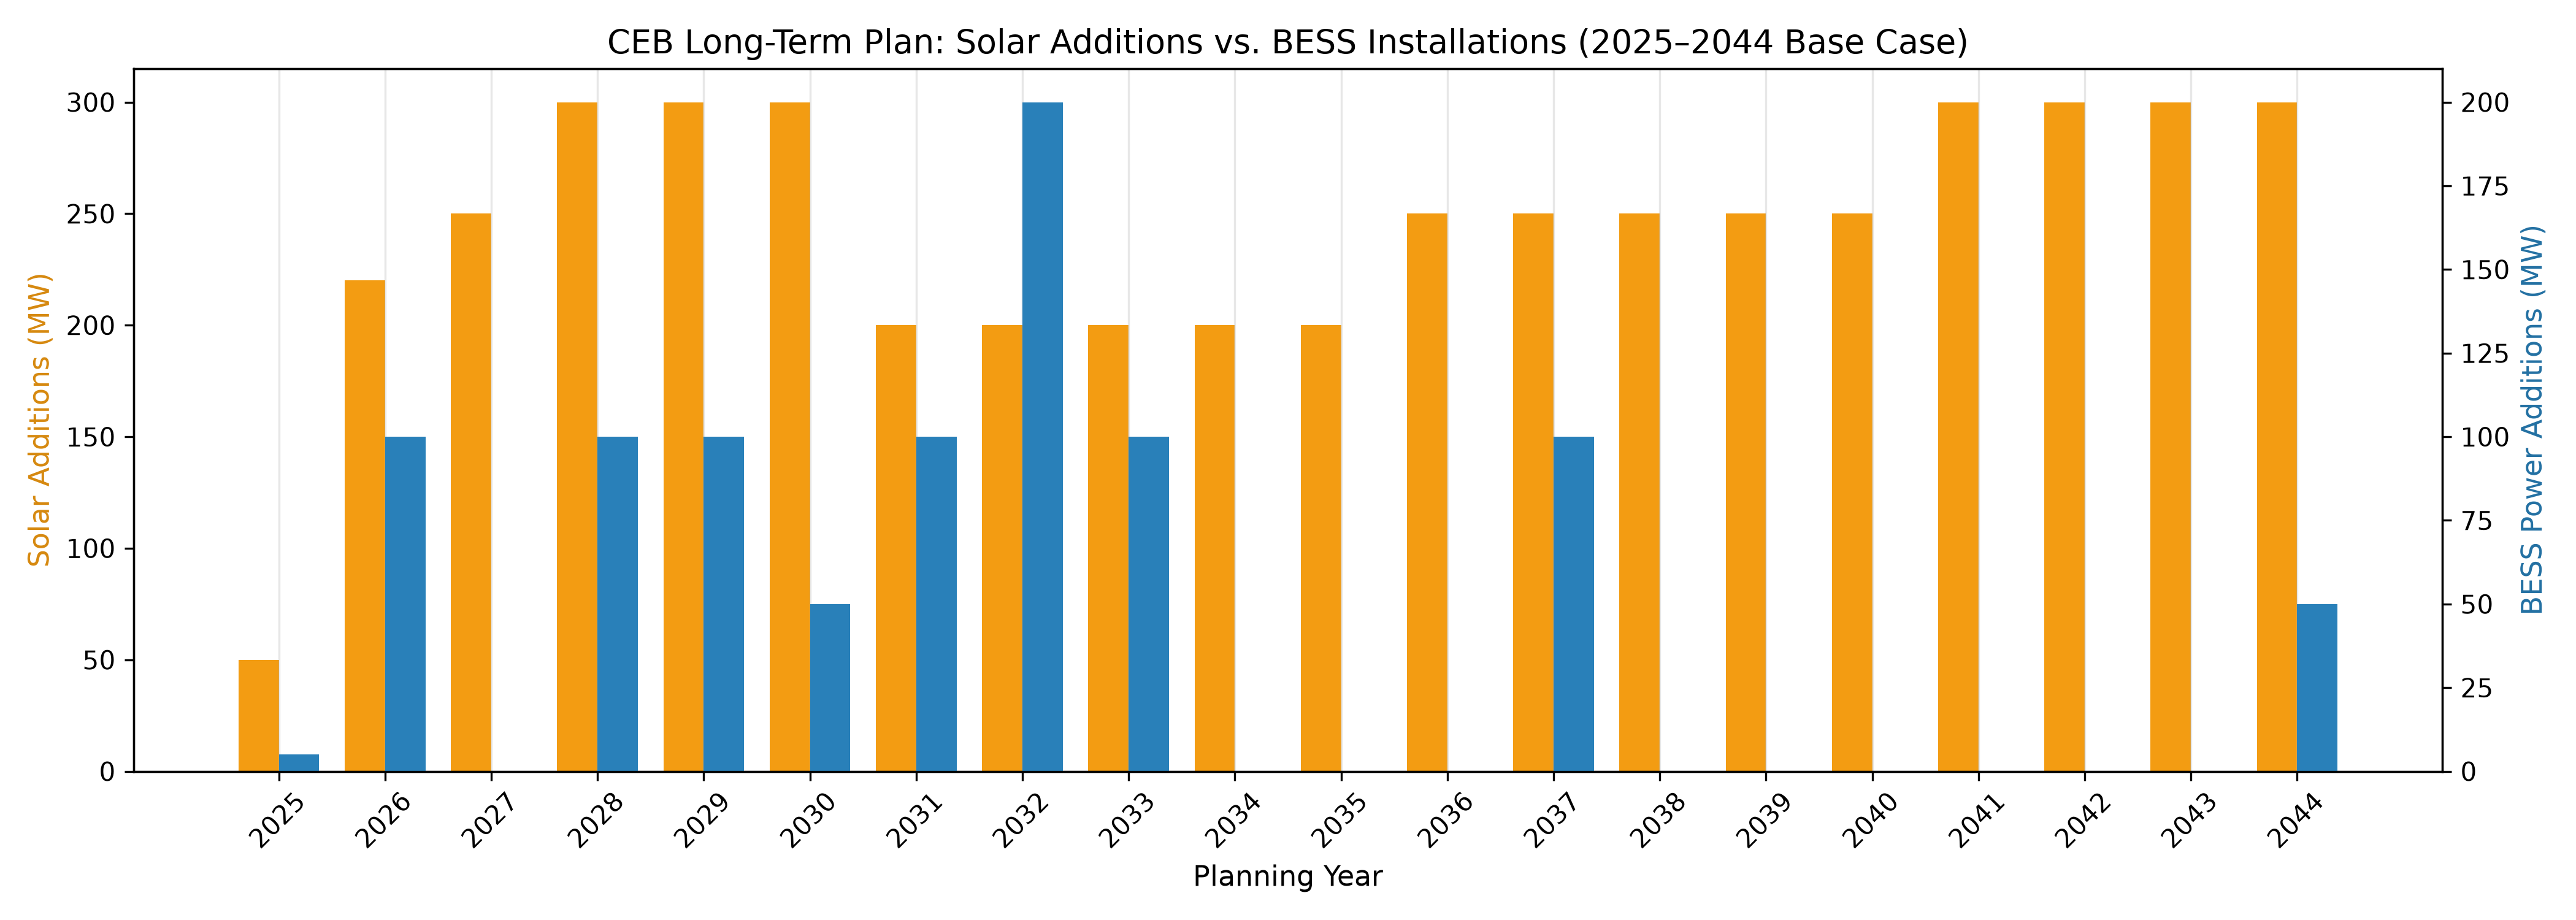

In [6]:
GRAPHS = ROOT / "results" / "graphs"
GRAPHS.mkdir(parents=True, exist_ok=True)

if not expansion.empty and {"planning_year", "bess_power_addition_mw", "grid_connected_solar_addition_mw"}.issubset(expansion.columns):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    years = expansion["planning_year"]
    solar_add = pd.to_numeric(expansion["grid_connected_solar_addition_mw"], errors="coerce").fillna(0)
    bess_add = pd.to_numeric(expansion["bess_power_addition_mw"], errors="coerce").fillna(0)

    width = 0.38
    bars1 = ax1.bar(years - width/2, solar_add, width=width, label="Planned Solar Additions (MW)", color="#f39c12")
    ax1.set_ylabel("Solar Additions (MW)", color="#d68910", fontsize=11)
    ax1.set_xlabel("Planning Year", fontsize=11)
    ax1.set_xticks(years)
    ax1.set_xticklabels(years, rotation=45)

    ax2 = ax1.twinx()
    bars2 = ax2.bar(years + width/2, bess_add, width=width, label="Planned BESS Power Additions (MW)", color="#2980b9")
    ax2.set_ylabel("BESS Power Additions (MW)", color="#2471a3", fontsize=11)

    ax1.set_title("CEB Long-Term Plan: Solar Additions vs. BESS Installations (2025–2044 Base Case)", fontsize=13)
    ax1.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(GRAPHS / "ceb_planned_solar_storage_additions.png", dpi=300)
    plt.show()
else:
    print("CEB planning benchmark data is unavailable.")

### Save selected data

In [7]:
capacity.to_csv(
    RESULTS / "ceb_capacity_analysis_input.csv",
    index=False
)

generation.to_csv(
    RESULTS / "ceb_generation_analysis_input.csv",
    index=False
)

demand.to_csv(
    RESULTS / "ceb_demand_analysis_input.csv",
    index=False
)

expansion.to_csv(
    RESULTS / "ceb_expansion_analysis_input.csv",
    index=False
)